<a href="https://colab.research.google.com/github/Tobkubos/Systemy_AI/blob/main/SystemyAI_TobiaszKubiak_Lab6_IMDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [21]:
# Twoje rozwiązanie

# PUNKT 1 - wczytanie zbioru
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)                                   # DatasetDict: train / test / unsupervised
    train_df = imdb["train"].to_pandas()          # kolumny: text, label
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)
train_df.head()

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [22]:
# PUNKT 2 - zamiana <br> na spacje
def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)

train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])
print("recenzji z '<br />' po czyszczeniu:", train_df["text"].str.contains("<br />").sum())

recenzji z '<br />' po czyszczeniu: 0


In [23]:
# PUNKT 3 - class_share (udział klas w train_df) i median_words (mediana liczby słów w recenzji treningowej)
class_share = train_df["label"].value_counts(normalize=True)
median_words = train_df["text"].apply(lambda t: len(t.split())).median()
print(class_share, median_words)

label
0    0.5
1    0.5
Name: proportion, dtype: float64 173.0


In [24]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [25]:
# Twoje rozwiązanie
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000)
}

wiersze = []

for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), train_df["text"], train_df["label"], cv=cv)
    wiersze.append({
        "model": nazwa,
        "CV": r["test_score"].mean(),
        "CV odch.": r["test_score"].std(),
        "czas uczenia [s]": r["fit_time"].mean()
    })
porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie

,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.86168,0.001526,3.613135
liniowy SVM,0.89324,0.000931,4.607949
regresja logistyczna,0.88540,0.002478,6.245737


In [26]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

In [27]:
# naiwny Bayes          :     81.9 -> 86.2
# liniowy SVM           :     86.2 -> 89.3
# regresja logistyczna  :     84.6 -> 88.5

# Większa próbka danych pozwoliła na polepszenie wszystkich modeli.
# W obu przypadkach każdy z nich zyskał kilka punktów.
# Kolejność modeli się nie zmieniła.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [28]:
# Wielkości macierzy unigramów oraz unigramów+bigramów
vec_uni = TfidfVectorizer(min_df=2, ngram_range=(1, 1))
matrix_uni = vec_uni.fit_transform(train_df["text"])
print("Wielkość macierzy unigramów (1, 1):", matrix_uni.shape)

vec_bi = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
matrix_bi = vec_bi.fit_transform(train_df["text"])
print("Wielkość macierzy unigramów + bigramów (1, 2):", matrix_bi.shape)
print("-" * 50)

# GridSearchCV
from sklearn.model_selection import GridSearchCV

pipeline = make_pipeline(TfidfVectorizer(min_df=2), LinearSVC())
gs = GridSearchCV(pipeline, param_grid={
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1]}, cv=cv)

gs.fit(train_df["text"], train_df["label"])
print(gs.best_params_)
print(gs.best_score_)

Wielkość macierzy unigramów (1, 1): (25000, 44797)
Wielkość macierzy unigramów + bigramów (1, 2): (25000, 436597)
--------------------------------------------------
{'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
0.9064398669059314


In [29]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

In [30]:
# na pełnym zbiorze wynik jest zauważalny (0.851 -> 0.906)


# Większy zbiór pomaga bigramom ze względu na to,
# że z powodu większej próbki danych, każda para słów pojawia się częściej.


# Model z bigramami uczy się około 3-4 razy wolniej niż standardowy model.
#
# Przycyzną tego jest wzrost wymiarowości cech,
# (liczba kolumn w macierzy rzadkiej rośnie z kilkudziesięciu tysięcy do ponad 400 000).
#
# Generowanie par sąsiednich słów obciąża proces tokenizacji i wektoryzacji tekstu.
#
# Większa macierz rzadka wymaga znacznie więcej pamięci oraz operacji podczas
# optymalizacji wag modelu.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

              precision    recall  f1-score   support

           0       0.90      0.91      0.90     12500
           1       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



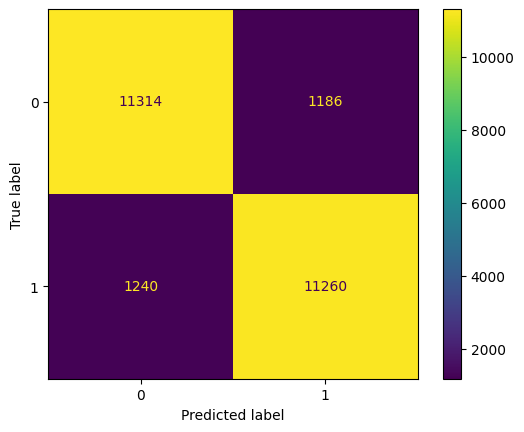

In [31]:
# Twoje rozwiązanie
acc_test = gs.score(test_df["text"], test_df["label"])
model_koncowy = gs.best_estimator_

y_pred = model_koncowy.predict(test_df["text"])

ConfusionMatrixDisplay.from_predictions(test_df["label"], y_pred)
print(classification_report(test_df["label"], y_pred))

In [32]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [33]:
# Twoje rozwiązanie
y_test = test_df["label"]

model_koncowy = gs.best_estimator_
wagi = pd.Series(model_koncowy[-1].coef_[0], index=model_koncowy[0].get_feature_names_out())
wagi = wagi.sort_values()
print(wagi.head(15))
print(wagi.tail(15))

bledy = test_df.copy()
bledy["pred"] = model_koncowy.predict(test_df["text"])
bledy = bledy[bledy["label"] != bledy["pred"]]
print("Liczba błędów:", len(bledy))
print("-" * 50)
print(bledy["text"].iloc[0][:500])
print("-" * 50)
print(bledy["text"].iloc[1][:500])
print("-" * 50)
print(bledy["text"].iloc[2][:500])

print("\n TEST WŁASNYCH RECENZJI ")

moje_recenzje = [
    "This was an absolute masterpiece! The acting was brilliant, the screenplay was superb, and I loved every single second of it. Truly amazing.", # Pozytywna
    "What a terrible waste of time. The plot was completely boring and the acting was awful. Avoid at all costs!",                                  # Negatywna
    "This is not a bad movie at all, despite what critics say. In fact, it was surprisingly enjoyable and fun.",                                    # Pozytywna z negacją ("not a bad movie")
    "Oh, brilliant! Another movie where the main character spends two hours staring at a wall. I absolutely loved being bored to death.",           # Ironiczna
    "I went in expecting a disaster, but I came out incredibly happy. The cinematography was perfect and the cast did an excellent job."            # Pozytywna
]

predykcje = model_koncowy.predict(moje_recenzje)

for i, (recenzja, pred) in enumerate(zip(moje_recenzje, predykcje), 1):
    sentiment = "Pozytywna (1)" if pred == 1 else "Negatywna (0)"
    print(f"Recenzja {i}: {recenzja}")
    print(f"Predykcja modelu: {sentiment}\n")

worst            -4.186860
awful            -3.717987
bad              -3.639969
boring           -3.461435
poor             -3.270281
the worst        -3.183396
waste            -2.919468
disappointment   -2.604945
terrible         -2.583009
worse            -2.566881
poorly           -2.510668
disappointing    -2.462955
dull             -2.420053
unfortunately    -2.395830
annoying         -2.333171
dtype: float64
best         1.835280
favorite     1.853958
bit          1.855964
loved        1.876260
superb       1.906072
brilliant    1.945156
the best     1.955429
enjoyable    1.964973
today        2.203575
amazing      2.208377
fun          2.286091
wonderful    2.565873
perfect      2.751831
excellent    3.236597
great        3.571217
dtype: float64
Liczba błędów: 2426
--------------------------------------------------
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best p

In [34]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

In [35]:
# Wyodrębnienie bigramów - podgląd wag
bigramy_wagi = wagi[wagi.index.str.contains(" ")]

print("Najważniejsze negatywne bigramy:")
print(bigramy_wagi.head(15))
print("\nNajważniejsze pozytywne bigramy:")
print(bigramy_wagi.tail(15))

Najważniejsze negatywne bigramy:
the worst      -3.183396
not worth      -1.926074
at all         -1.866331
waste of       -1.691102
than this      -1.680275
not good       -1.615698
at best        -1.537989
not even       -1.533275
not very       -1.443984
the original   -1.436952
it just        -1.386509
way too        -1.333477
just not       -1.280261
none of        -1.235795
the problem    -1.224722
dtype: float64

Najważniejsze pozytywne bigramy:
my favorite         1.266459
to all              1.269935
love this           1.302116
10 10               1.316775
of what             1.342270
on dvd              1.344836
watch it            1.356774
very well           1.362170
very good           1.379135
definitely worth    1.435620
well worth          1.540778
must see            1.590395
this is             1.636565
better than         1.675651
the best            1.955429
dtype: float64


In [36]:
# 1.
# Najważniejsze negatywne bigramy:
# the worst      -3.183395
# not worth      -1.926074
# at all         -1.866331
# waste of       -1.691102
# than this      -1.680275
#
# Najważniejsze pozytywne bigramy:
# the best            1.955430
# better than         1.675651
# this is             1.636565
# must see            1.590395
# well worth          1.540778
#
#
# 2.
# Model poprawnie zidentyfikował, że dodanie słowa modyfikującego całkowicie odwraca znaczenie
# PRZYKŁAD: "worth" -> "not worth"
# Model nauczył się wykrywać popularne zwroty służące do ekspresji silnych emocji
# PRZYKŁAD: "must see", "waste of"
#
# 3. Wszystkie recenzje ocenił dobrze - brak błędów
#
# 4. Model musiałby podchodzić do każdej recenzji osobiście i
# umieć rozumieć kontekst całej wypowiedzi, ponieważ niektóre z nich mogą być
# napisane ironicznie bądź zawierać pewne wyjąki językowe,
# kiedy złe określenie może oznaczać coś dobrego.